# GRU — evaluación en test

**Única evaluación en test** de los modelos GRU ya entrenados. No se entrena ni se ajusta nada con estos resultados.

- **Modelo principal:** `aleatorio_w10` (W=10, orden sorteado dentro de cada minuto).
- **Referencias:** `baseline_w10` (W=10, orden del CSV) y `w1` (solo el flujo objetivo).
- **Umbral:** el `umbral_f2` elegido en validación para cada semilla (`*_seeds.json`). No se reelige en test.

Los tres modelos se evalúan sobre las mismas filas objetivo: la intersección de las filas con secuencia en las variantes `csv` y `aleatorio`.

## 1. Imports y configuración

In [1]:
import sys
sys.path.append("../..")  # raíz del repo, para poder importar src.*

import json
import os

import keras
import numpy as np
import pandas as pd

from src.models.gru.evaluation import metricas_con_umbral
from src.preprocessing.clean import cargar_dataset_limpio

In [2]:
SEMILLAS = [0, 1, 2, 3, 4]

W = 10
DATA_DIR = "../../data/sequences"
PROCESSED_PATH = "../../data/processed/wednesday_low_and_slow_clean.csv"
RESULTS_DIR = "../../results/gru/03_evaluacion_test"

# El primero es el modelo principal; los otros dos son referencias
MODELOS = {
    "aleatorio_w10": {
        "models_dir": "../../models/gru/02_ablaciones",
        "seeds_path": "../../results/gru/02_ablaciones/aleatorio_w10_seeds.json",
    },
    "baseline_w10": {
        "models_dir": "../../models/gru/01_baseline",
        "seeds_path": "../../results/gru/01_baseline/baseline_w10_seeds.json",
    },
    "w1": {
        "models_dir": "../../models/gru/02_ablaciones",
        "seeds_path": "../../results/gru/02_ablaciones/w1_seeds.json",
    },
}
TIPOS_ATAQUE = {"DoS slowloris": "recall_slowloris", "DoS Slowhttptest": "recall_slowhttptest"}

# Umbral de cada (modelo, semilla): el umbral_f2 elegido en validación
UMBRALES = {}
for nombre, info in MODELOS.items():
    with open(info["seeds_path"], encoding="utf-8") as f:
        seeds = json.load(f)
    assert seeds["conjunto"] == "validacion" and seeds["semillas"] == SEMILLAS, nombre
    UMBRALES[nombre] = {fila["semilla"]: fila["umbral_f2"] for fila in seeds["por_semilla"]}

pd.DataFrame(UMBRALES).rename_axis("semilla")

,aleatorio_w10,baseline_w10,w1
semilla,,,
0,0.106,0.076,0.010
1,0.125,0.239,0.472
2,0.066,0.835,0.113
3,0.070,0.146,0.507
4,0.103,0.744,0.999


## 2. Carga de test y filas comunes

`idx_*` es el índice de la fila objetivo (último paso) de cada secuencia: el índice de `X_test` que devuelve `train_test_split_by_flow()`. Las variantes `csv` y `aleatorio` tienen las mismas filas en test, pero descartan filas distintas al inicio de cada bloque (las primeras W−1 no tienen historia), así que se evalúa sobre la intersección.

In [3]:
X_csv = np.load(f"{DATA_DIR}/X_test_w{W}.npy")
y_csv = np.load(f"{DATA_DIR}/y_test_w{W}.npy")
idx_csv = np.load(f"{DATA_DIR}/idx_test_w{W}.npy")
X_ale = np.load(f"{DATA_DIR}/X_test_w{W}_aleatorio.npy")
y_ale = np.load(f"{DATA_DIR}/y_test_w{W}_aleatorio.npy")
idx_ale = np.load(f"{DATA_DIR}/idx_test_w{W}_aleatorio.npy")

for idx, y, X in ((idx_csv, y_csv, X_csv), (idx_ale, y_ale, X_ale)):
    assert len(idx) == len(y) == len(X)
    assert len(np.unique(idx)) == len(idx)

idx_comun = np.intersect1d(idx_csv, idx_ale)
pos_csv = pd.Index(idx_csv).get_indexer(idx_comun)
pos_ale = pd.Index(idx_ale).get_indexer(idx_comun)

y_test = y_csv[pos_csv]
assert np.array_equal(y_test, y_ale[pos_ale]), "Etiquetas distintas entre csv y aleatorio en las filas comunes"

# W=1: último paso de cada ventana csv W=10, igual que en 02_ablaciones
X_TEST = {
    "aleatorio_w10": X_ale[pos_ale],
    "baseline_w10": X_csv[pos_csv],
    "w1": X_csv[pos_csv][:, -1:, :],
}
# La fila objetivo es la misma en las tres entradas
assert np.array_equal(X_TEST["aleatorio_w10"][:, -1, :], X_TEST["baseline_w10"][:, -1, :])
assert X_TEST["w1"].shape == (len(y_test), 1, 59)

print(f"Secuencias de test -> csv: {len(idx_csv)} | aleatorio: {len(idx_ale)}")
print(f"Filas comunes: {len(idx_comun)} | ataques: {int(y_test.sum())} | benignos: {int((y_test == 0).sum())}")
print(f"Ataques fuera de la intersección -> csv: {int(y_csv.sum() - y_test.sum())} | aleatorio: {int(y_ale.sum() - y_test.sum())}")

del X_csv, X_ale

Secuencias de test -> csv: 66499 | aleatorio: 66499
Filas comunes: 66454 | ataques: 1164 | benignos: 65290
Ataques fuera de la intersección -> csv: 2 | aleatorio: 9


## 3. Tipo de ataque de cada fila común

In [4]:
import joblib

from src.models.gru.sequences import FEATURE_COLUMNS
from src.preprocessing.clean import _log_con_signo

# Mismo orden e índice que usa train_test_split_by_flow(desempate="csv")
df = cargar_dataset_limpio(PROCESSED_PATH)
df = df.sort_values("Timestamp", kind="stable").reset_index(drop=True)

assert np.array_equal(df.loc[idx_comun, "label_binaria"].to_numpy(), y_test), (
    "Los índices no corresponden al CSV procesado actual"
)

# Verificación por features: las filas del CSV, con la misma transformación de
# build_gru_sequences.py (log con signo + scaler_csv.joblib), deben coincidir con
# el último paso de cada secuencia
scaler = joblib.load(f"{DATA_DIR}/scaler_csv.joblib")
assert list(scaler.feature_names_in_) == FEATURE_COLUMNS, (
    "El scaler no se ajustó sobre FEATURE_COLUMNS en ese orden"
)
esperado = scaler.transform(_log_con_signo(df.loc[idx_comun, FEATURE_COLUMNS].astype(float)))
objetivo = X_TEST["baseline_w10"][:, -1, :]
assert np.allclose(esperado, objetivo, atol=1e-5), (
    "Los índices no apuntan a las filas objetivo de las secuencias: "
    f"{int((~np.isclose(esperado, objetivo, atol=1e-5)).any(axis=1).sum())} de {len(idx_comun)} filas "
    f"difieren en alguna feature (diferencia máxima {np.abs(esperado - objetivo).max():.3g})"
)
print(f"OK: las {len(idx_comun)} filas del CSV coinciden por features con el último paso de sus secuencias.")

label_test = df.loc[idx_comun, "Label"].to_numpy()
del df, esperado, objetivo

ataques_por_tipo = {tipo: int((label_test == tipo).sum()) for tipo in TIPOS_ATAQUE}
assert sum(ataques_por_tipo.values()) == int(y_test.sum())
print("Ataques por tipo en las filas comunes:", ataques_por_tipo)

OK: las 66454 filas del CSV coinciden por features con el último paso de sus secuencias.
Ataques por tipo en las filas comunes: {'DoS slowloris': 914, 'DoS Slowhttptest': 250}


## 4. Evaluación por modelo y semilla

In [5]:
os.makedirs(RESULTS_DIR, exist_ok=True)

filas = []
for nombre, info in MODELOS.items():
    for seed in SEMILLAS:
        keras.backend.clear_session()
        model = keras.models.load_model(f"{info['models_dir']}/{nombre}_seed{seed}.keras")
        proba = model.predict(X_TEST[nombre], verbose=0).ravel()
        np.save(f"{RESULTS_DIR}/{nombre}_seed{seed}_test_proba.npy", proba)
        del model

        umbral = UMBRALES[nombre][seed]
        pred = proba >= umbral
        fila = {
            "modelo": nombre,
            "semilla": seed,
            "umbral_f2_val": umbral,
            **metricas_con_umbral(y_test, proba, umbral),
            **{col: float(pred[label_test == tipo].mean()) for tipo, col in TIPOS_ATAQUE.items()},
        }
        filas.append(fila)
        print(fila)


{'modelo': 'aleatorio_w10', 'semilla': 0, 'umbral_f2_val': 0.106, 'roc_auc': 0.9972963737256828, 'pr_auc': 0.9822890557411206, 'f2': 0.9493883023294787, 'recall': 0.9733676975945017, 'precision': 0.8642257818459191, 'fn': 31, 'fp': 178, 'f1': 0.9155555555555556, 'accuracy': 0.9968549673458332, 'tp': 1133, 'tn': 65112, 'recall_slowloris': 0.9912472647702407, 'recall_slowhttptest': 0.908}
{'modelo': 'aleatorio_w10', 'semilla': 1, 'umbral_f2_val': 0.125, 'roc_auc': 0.998258753307343, 'pr_auc': 0.9864475873492254, 'f2': 0.967769152885589, 'recall': 0.9853951890034365, 'precision': 0.9031496062992126, 'fn': 17, 'fp': 123, 'f1': 0.942481511914544, 'accuracy': 0.9978932795618022, 'tp': 1147, 'tn': 65167, 'recall_slowloris': 0.9934354485776805, 'recall_slowhttptest': 0.956}
{'modelo': 'aleatorio_w10', 'semilla': 2, 'umbral_f2_val': 0.066, 'roc_auc': 0.9985427163714204, 'pr_auc': 0.9858507170836948, 'f2': 0.9529871011541072, 'recall': 0.9647766323024055, 'precision': 0.9085760517799353, 'fn': 

## 5. Resultados en test

Tabla por semilla y resumen por modelo: media ± desviación estándar muestral (ddof=1) sobre las 5 semillas.

In [6]:
tabla = pd.DataFrame(filas).set_index(["modelo", "semilla"])
tabla

umbral_f2_val   roc_auc    pr_auc        f2    recall  \
modelo        semilla                                                          
aleatorio_w10 0                0.106  0.997296  0.982289  0.949388  0.973368   
              1                0.125  0.998259  0.986448  0.967769  0.985395   
              2                0.066  0.998543  0.985851  0.952987  0.964777   
              3                0.070  0.997042  0.986271  0.959953  0.980241   
              4                0.103  0.997906  0.984584  0.951610  0.959622   
baseline_w10  0                0.076  0.999617  0.998426  0.997594  0.997423   
              1                0.239  0.999998  0.999889  0.996392  0.996564   
              2                0.835  0.999991  0.999632  0.995012  0.993986   
              3                0.146  0.999449  0.996434  0.956175  0.948454   
              4                0.744  0.999980  0.999403  0.996567  0.997423   
w1            0                0.010  0.999222  0.992220  0.973556  0.993127   
              1                0.472  0.998437  0.993606  0.989387  0.993127   
              2                0.113  0.998732  0.991909  0.984332  0.993127   
              3                0.507  0.998933  0.989702  0.979145  0.992268   
              4                0.999  0.998751  0.989896  0.847126  0.817869   

                       precision   fn   fp        f1  accuracy    tp     tn  \
modelo        semilla                                                         
aleatorio_w10 0         0.864226   31  178  0.915556  0.996855  1133  65112   
              1         0.903150   17  123  0.942482  0.997893  1147  65167   
              2         0.908576   41  113  0.935833  0.997683  1123  65177   
              3         0.886558   23  146  0.931049  0.997457  1141  65144   
              4         0.920857   47   96  0.939840  0.997848  1117  65194   
baseline_w10  0         0.998280    3    2  0.997851  0.999925  1161  65288   
              1         0.995708    4    5  0.996136  0.999865  1160  65285   
              2         0.999136    7    1  0.996555  0.999880  1157  65289   
              3         0.988362   60   13  0.967996  0.998901  1104  65277   
              4         0.993157    3    8  0.995285  0.999834  1161  65282   
w1            0         0.902420    8  125  0.945603  0.997999  1156  65165   
              1         0.974705    8   30  0.983830  0.999428  1156  65260   
              2         0.950658    8   60  0.971429  0.998977  1156  65230   
              3         0.929952    9   87  0.960100  0.998555  1155  65203   
              4         0.988577  212   11  0.895157  0.996644   952  65279   

                       recall_slowloris  recall_slowhttptest  
modelo        semilla                                         
aleatorio_w10 0                0.991247                0.908  
              1                0.993435                0.956  
              2                0.984683                0.892  
              3                0.993435                0.932  
              4                0.980306                0.884  
baseline_w10  0                0.996718                1.000  
              1                0.997812                0.992  
              2                0.994530                0.992  
              3                0.934354                1.000  
              4                0.997812                0.996  
w1            0                0.993435                0.992  
              1                0.993435                0.992  
              2                0.993435                0.992  
              3                0.993435                0.988  
              4                0.810722                0.844

In [7]:
media = tabla.groupby("modelo", sort=False).mean()
std = tabla.groupby("modelo", sort=False).std(ddof=1)

tabla_resumen = pd.DataFrame({
    col: [f"{m:.6g} ± {s:.2g}" for m, s in zip(media[col], std[col])] for col in tabla.columns
}, index=media.index)
tabla_resumen

,umbral_f2_val,roc_auc,pr_auc,f2,recall,precision,fn,fp,f1,accuracy,tp,tn,recall_slowloris,recall_slowhttptest
modelo,,,,,,,,,,,,,,
aleatorio_w10,0.094 ± 0.025,0.997809 ± 0.00063,0.985089 ± 0.0017,0.956342 ± 0.0075,0.97268 ± 0.011,0.896673 ± 0.022,31.8 ± 12,131.2 ± 32,0.932952 ± 0.011,0.997547 ± 0.00042,1132.2 ± 12,65158.8 ± 32,0.988621 ± 0.0059,0.9144 ± 0.03
baseline_w10,0.408 ± 0.35,0.999807 ± 0.00026,0.998757 ± 0.0014,0.988348 ± 0.018,0.98677 ± 0.021,0.994929 ± 0.0044,15.4 ± 25,5.8 ± 4.9,0.990765 ± 0.013,0.999681 ± 0.00044,1148.6 ± 25,65284.2 ± 4.9,0.984245 ± 0.028,0.996 ± 0.004
w1,0.4202 ± 0.39,0.998815 ± 0.00029,0.991467 ± 0.0017,0.954709 ± 0.06,0.957904 ± 0.078,0.949262 ± 0.035,49 ± 91,62.6 ± 45,0.951224 ± 0.034,0.998321 ± 0.0011,1115 ± 91,65227.4 ± 45,0.956893 ± 0.082,0.9616 ± 0.066


In [8]:
RESULTADOS_PATH = f"{RESULTS_DIR}/test_resultados.json"
IDX_PATH = f"{RESULTS_DIR}/idx_test_comun.npy"

resultado = {
    "conjunto": "test",
    "modelo_principal": "aleatorio_w10",
    "umbral": "umbral_f2 de validación de cada semilla, sin reelegir en test",
    "semillas": SEMILLAS,
    "n_filas": int(len(y_test)),
    "n_ataques": int(y_test.sum()),
    "ataques_por_tipo": ataques_por_tipo,
    "idx_test_comun": (
        "idx_test_comun.npy: índice de X_test devuelto por "
        "train_test_split_by_flow(desempate='csv') para las filas evaluadas"
    ),
    "por_semilla": filas,
    "media": media.to_dict(orient="index"),
    "std": std.to_dict(orient="index"),
}

with open(RESULTADOS_PATH, "w", encoding="utf-8") as f:
    json.dump(resultado, f, indent=2, ensure_ascii=False)
np.save(IDX_PATH, idx_comun)
print(f"Resultados guardados en: {RESULTADOS_PATH}")
print(f"Índices de las filas evaluadas guardados en: {IDX_PATH}")

Resultados guardados en: ../../results/gru/03_evaluacion_test/test_resultados.json
Índices de las filas evaluadas guardados en: ../../results/gru/03_evaluacion_test/idx_test_comun.npy


## 6. Figuras y tablas

Se generan a partir de las probabilidades de test ya guardadas en `RESULTS_DIR`; no se cargan modelos ni se vuelve a predecir. El umbral de cada semilla es el mismo `umbral_f2` de validación.

In [9]:
from sklearn.metrics import confusion_matrix

from src.models.gru.evaluation import (
    plot_curvas_por_semilla,
    plot_matrices_confusion,
    plot_recall_por_tipo,
)

# Solo para las figuras: las claves internas, los JSON y los CSV conservan el nombre corto
NOMBRES_MODELO = {
    "aleatorio_w10": "GRU W=10 (orden aleatorio)",
    "baseline_w10": "GRU W=10 (orden CSV)",
    "w1": "GRU W=1",
}


def con_nombres(por_modelo):
    return {NOMBRES_MODELO[nombre]: valor for nombre, valor in por_modelo.items()}


PROBAS = {
    nombre: {
        seed: np.load(f"{RESULTS_DIR}/{nombre}_seed{seed}_test_proba.npy") for seed in SEMILLAS
    }
    for nombre in MODELOS
}
PREDICCIONES = {
    nombre: {seed: PROBAS[nombre][seed] >= UMBRALES[nombre][seed] for seed in SEMILLAS}
    for nombre in MODELOS
}
assert all(len(p) == len(y_test) for por_semilla in PROBAS.values() for p in por_semilla.values())

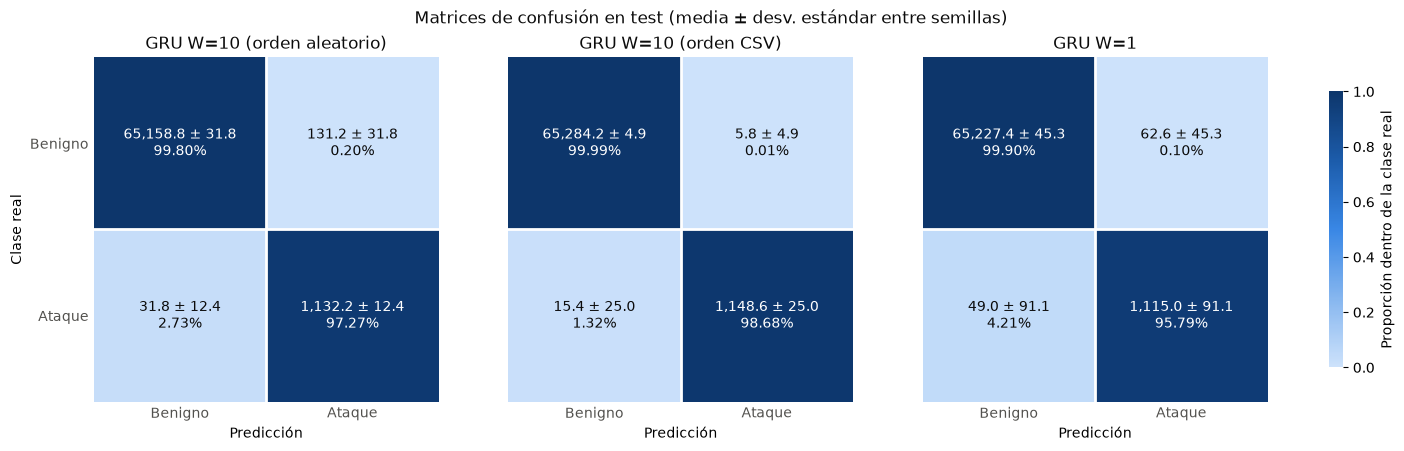

In [10]:
conteos = {
    nombre: np.array([
        confusion_matrix(y_test, PREDICCIONES[nombre][seed], labels=[0, 1]) for seed in SEMILLAS
    ])
    for nombre in MODELOS
}

matrices_por_semilla = pd.DataFrame([
    {
        "modelo": nombre, "semilla": seed, "umbral_f2_val": UMBRALES[nombre][seed],
        "tn": int(m[0, 0]), "fp": int(m[0, 1]), "fn": int(m[1, 0]), "tp": int(m[1, 1]),
    }
    for nombre in MODELOS
    for seed, m in zip(SEMILLAS, conteos[nombre])
])
matrices_por_semilla.to_csv(f"{RESULTS_DIR}/matrices_confusion_test_por_semilla.csv", index=False)

fig = plot_matrices_confusion(
    con_nombres(conteos), save_path=f"{RESULTS_DIR}/matrices_confusion_test.png",
)

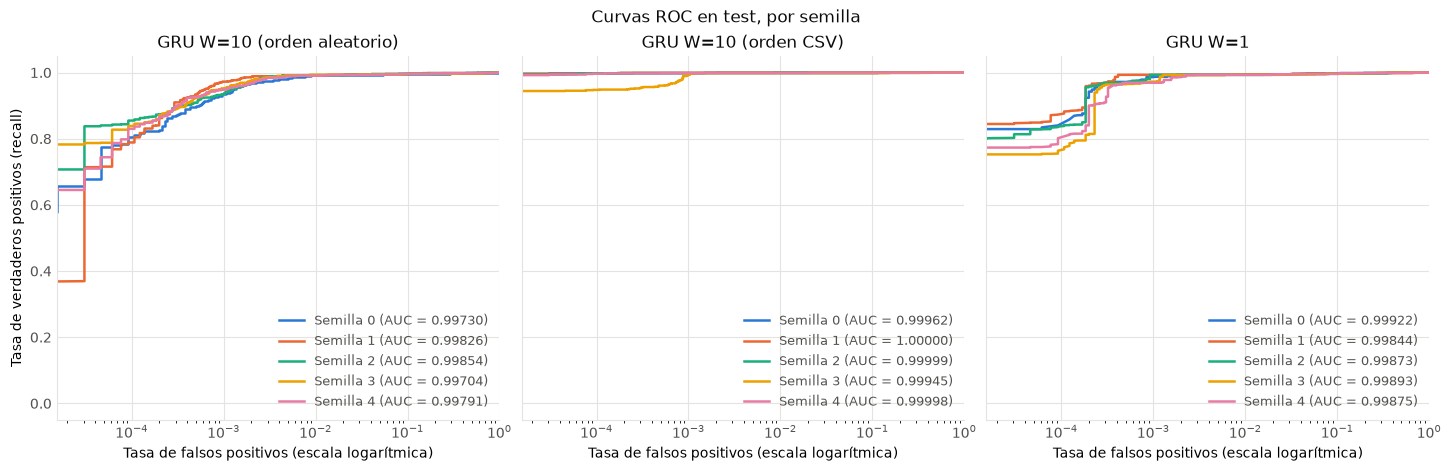

In [11]:
fig = plot_curvas_por_semilla(
    y_test, con_nombres(PROBAS), tipo="roc", fpr_log=True,
    save_path=f"{RESULTS_DIR}/curvas_roc_test.png",
)

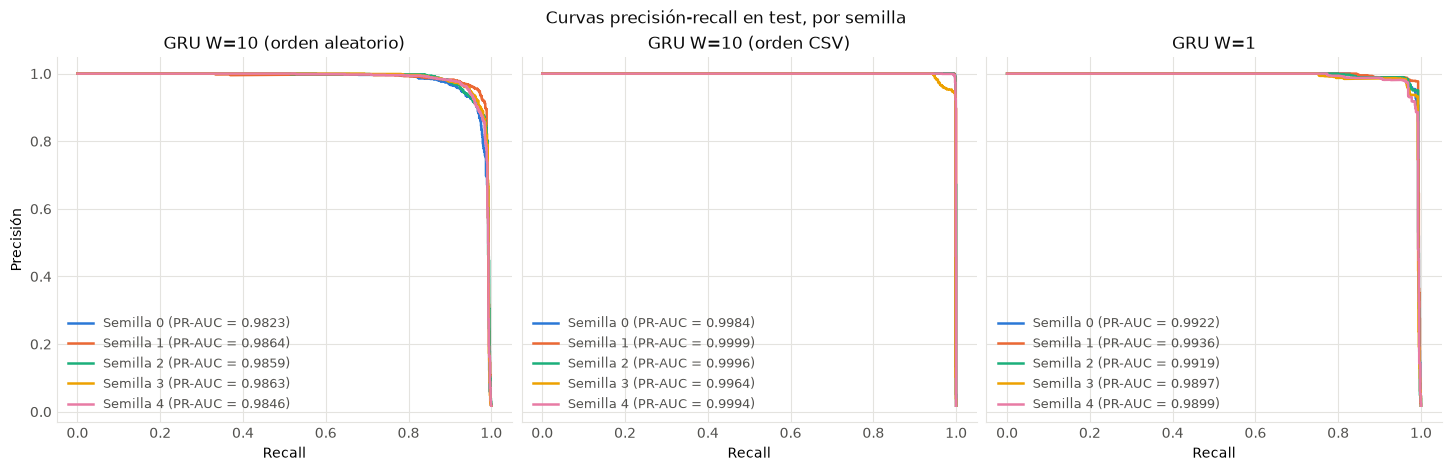

In [12]:
fig = plot_curvas_por_semilla(
    y_test, con_nombres(PROBAS), tipo="pr", save_path=f"{RESULTS_DIR}/curvas_pr_test.png",
)

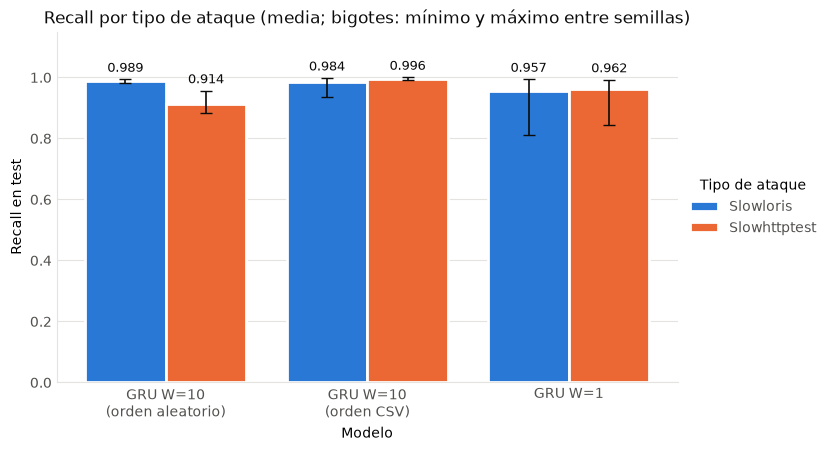

In [13]:
NOMBRES_TIPO = {"DoS slowloris": "Slowloris", "DoS Slowhttptest": "Slowhttptest"}

recall_por_tipo = pd.DataFrame([
    {
        "modelo": NOMBRES_MODELO[nombre], "semilla": seed,
        **{
            NOMBRES_TIPO[tipo]: float(PREDICCIONES[nombre][seed][label_test == tipo].mean())
            for tipo in TIPOS_ATAQUE
        },
    }
    for nombre in MODELOS
    for seed in SEMILLAS
]).groupby("modelo", sort=False)[list(NOMBRES_TIPO.values())]

fig = plot_recall_por_tipo(
    recall_por_tipo.mean(), recall_por_tipo.min(), recall_por_tipo.max(),
    save_path=f"{RESULTS_DIR}/recall_por_tipo_test.png",
)

In [14]:
# utf-8-sig: para que Excel muestre bien el símbolo ±
tabla.to_csv(f"{RESULTS_DIR}/tabla_test_por_semilla.csv")
tabla_resumen.to_csv(f"{RESULTS_DIR}/tabla_test_resumen.csv", encoding="utf-8-sig")

tiempos = {}
for nombre, info in MODELOS.items():
    with open(info["seeds_path"], encoding="utf-8") as f:
        tiempos[nombre] = [fila["tiempo_entrenamiento_s"] for fila in json.load(f)["por_semilla"]]
tiempos = pd.DataFrame(tiempos, index=pd.Index(SEMILLAS, name="semilla"))

tabla_tiempo = pd.DataFrame({"media_s": tiempos.mean(), "std_s": tiempos.std(ddof=1)}).rename_axis("modelo")
tabla_tiempo["media ± std (s)"] = [
    f"{m:.1f} ± {s:.1f}" for m, s in zip(tabla_tiempo["media_s"], tabla_tiempo["std_s"])
]
tabla_tiempo.to_csv(f"{RESULTS_DIR}/tiempo_entrenamiento.csv", encoding="utf-8-sig")
tabla_tiempo

,media_s,std_s,media ± std (s)
modelo,,,
aleatorio_w10,265.742563,56.595393,265.7 ± 56.6
baseline_w10,153.248808,41.279857,153.2 ± 41.3
w1,143.785816,56.433388,143.8 ± 56.4


## Conclusiones


- Se evaluaron 66,454 filas de test (1,164 ataques: 914 slowloris y 250 Slowhttptest), comunes a los tres modelos, cada uno con el umbral F2 elegido en validación por semilla.
- **Modelo principal (GRU W=10, orden aleatorio):** recall de 0.973 ± 0.011, es decir, 31.8 ± 12.4 ataques no detectados de 1,164. F1 de 0.933 ± 0.011, precision de 0.897 ± 0.022, ROC-AUC de 0.9978 ± 0.0006 y PR-AUC de 0.985 ± 0.002. Hay 131 ± 32 falsos positivos (0.20 % del tráfico benigno).
- El recall es de 0.989 ± 0.006 en slowloris y de 0.914 ± 0.030 en Slowhttptest, que concentra cerca de dos tercios de los falsos negativos.
- **GRU W=1:** recall de 0.958 ± 0.078, F1 de 0.951 ± 0.034, ROC-AUC de 0.9988 ± 0.0003 y PR-AUC de 0.991 ± 0.002. En cuatro semillas el recall es de 0.992–0.993, con 30 a 125 falsos positivos. En la semilla 4, el umbral elegido en validación (0.999) deja 212 falsos negativos.
- Con el orden sorteado dentro de cada minuto, la ventana de 10 flujos no mejora la detección respecto al flujo individual: W=1 tiene mayor recall en cuatro de cinco semillas, y su F1, ROC-AUC y PR-AUC medios también son mayores.
- **GRU W=10, orden CSV:** recall de 0.987 ± 0.021, F1 de 0.991 ± 0.013 y 5.8 ± 4.9 falsos positivos. Es el mejor de los tres porque aprovecha el agrupamiento por host del archivo (ver `02_ablaciones.ipynb`), así que es una cota optimista y no el desempeño esperado cuando ese orden no está disponible.
- La accuracy es ≥ 0.997 en los tres modelos. Con 98.2 % de filas benignas, no sirve para distinguirlos.
- Respecto a validación, el modelo principal baja de un recall de 0.989 a 0.973 y de una precision de 0.941 a 0.897. Test corresponde al último 15 % de cada bloque temporal.
- Los umbrales F2 elegidos en validación varían mucho entre semillas en los modelos W=10 (orden CSV) y W=1 (de 0.01 a 0.999), y el caso extremo no se trasladó a test. Las métricas independientes del umbral son estables entre semillas: la desviación estándar de ROC-AUC y PR-AUC es ≤ 0.002 en los tres modelos.
- Tiempo de entrenamiento por semilla, en CPU: 266 ± 57 s con orden aleatorio, 153 ± 41 s con orden CSV y 144 ± 56 s con W=1.
- Figuras: `matrices_confusion_test.png`, `curvas_roc_test.png`, `curvas_pr_test.png` y `recall_por_tipo_test.png`, en `results/gru/03_evaluacion_test/`.